In [1]:
import os
import pandas as pd
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import bambi as bmb
import arviz as az
from scipy.stats import gaussian_kde
import matplotlib.font_manager as fm
from matplotlib_scalebar.scalebar import ScaleBar
import matplotlib.patches as mpatches
from matplotlib import font_manager
import matplotlib as mpl

os.environ["SHAPE_RESTORE_SHX"] = "YES"
pd.set_option('display.max_columns', 50)

plt.rcParams["font.family"] = "Libertinus Serif"


In [2]:
TEKSTBREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7



def komma_decimalen(fig):
    """Decimale komma in de standaard-asopmaak (ook kleurenschalen); eigen
    opmaak (FuncFormatter, vaste labels) blijft ongemoeid."""
    from matplotlib import ticker

    class Komma(ticker.Formatter):
        def __init__(self, basis):
            self.basis = basis
        def set_locs(self, locs):
            self.basis.set_locs(locs)
        def __call__(self, x, pos=None):
            return self.basis(x, pos).replace(".", ",")
        def get_offset(self):
            return self.basis.get_offset().replace(".", ",")

    for ax in fig.axes:
        for as_ in (ax.xaxis, ax.yaxis):
            for kies, zet in ((as_.get_major_formatter, as_.set_major_formatter),
                              (as_.get_minor_formatter, as_.set_minor_formatter)):
                f = kies()
                if isinstance(f, (ticker.ScalarFormatter, ticker.LogFormatter)):
                    f.axis = as_
                    zet(Komma(f))

def pas_breedte_aan(fig, doel=108 / 25.4, tight=None):
    """Maakt de figuur zo breed dat de opgeslagen afbeelding (ook met bbox 'tight')
    precies `doel` inch breed is. De letters blijven even groot; alleen het
    grafiekvlak wordt iets breder of smaller. Zet ook de decimalen op de assen
    om naar een komma."""
    import matplotlib as mpl
    komma_decimalen(fig)
    if tight is None:
        tight = mpl.rcParams["savefig.bbox"] == "tight"
    pad = mpl.rcParams["savefig.pad_inches"] if tight else 0
    oorspronkelijk = fig.get_figwidth()
    for _ in range(6):
        fig.canvas.draw()
        breedte = (fig.get_tightbbox().width if tight else fig.get_figwidth()) + 2 * pad
        if abs(breedte - doel) < 0.004:
            break
        nieuw = fig.get_figwidth() + (doel - breedte)
        if nieuw < 0.5 * doel:
            # een legende of label is op zich al breder dan het doel
            fig.set_figwidth(oorspronkelijk)
            print(f"Let op: figuur past niet binnen {doel * 25.4:.0f} mm; breedte niet aangepast.")
            break
        fig.set_figwidth(nieuw)

SERIF = "Libertinus Serif"
FONTMAP = Path("fonts") 

beschikbaar = {f.name for f in font_manager.fontManager.ttflist}
if SERIF not in beschikbaar:
    print(f"{SERIF} niet gevonden; matplotlib valt terug op CMU Serif.")

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": [SERIF, "CMU Serif", "DejaVu Serif"],
    "font.size": CORPS,
    "axes.titlesize": CORPS,
    "axes.labelsize": CORPS,
    "xtick.labelsize": CORPS,
    "ytick.labelsize": CORPS,
    "legend.fontsize": CORPS,
    "mathtext.fontset": "custom",
    "mathtext.rm": SERIF,
    "mathtext.it": f"{SERIF}:italic",
    "mathtext.bf": f"{SERIF}:bold",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "savefig.bbox": "tight",
    "savefig.transparent": True,
    "savefig.dpi": 300,
})

def figsize(fractie=1.0, ratio=0.58):
    breedte = TEKSTBREEDTE * fractie
    return (breedte, breedte * ratio)

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [3]:
GIS    = Path("../../data/algemeen/gis")
OUTPUT = Path("../../fig/H6")

# Straten
STREETS_SHP      = GIS / "straten/1898_Street.shp"
STRAATZIJDEN_SHP = GIS / "straten/1898_straatzijden.shp"

# Verlichting
GAS_1889_SHP  = GIS / "infrastructuur/gasverlichting_1889.shp"
GAS_1919_SHP  = GIS / "infrastructuur/gasverlichting_1919.shp"
ELEK_1921_SHP = GIS / "infrastructuur/elektrischeverlichting_1921.shp"

# Tram en trein
PAARDENTRAM_1895_SHP      = GIS / "infrastructuur/paardentram_1895.shp"
ELEKTRISCHE_TRAM_1903_SHP = GIS / "infrastructuur/elektrischetram_1903.shp"
TREINSTATIONS_SHP         = GIS / "infrastructuur/treinstations_1885.shp"

# Ontspanning
PARKEN_WANDELINGEN_SHP = GIS / "infrastructuur/parken_en_openbarewandelingen_1894.shp"
DANSZALEN_1898_SHP     = GIS / "infrastructuur/danszalen_1898.shp"
DANSZALEN_1925_SHP     = GIS / "infrastructuur/danszalen_1925.shp"
HERBERGEN_SHP          = GIS / "infrastructuur/herbergen_1898.shp"

# Politie
POLITIE_VROEG_SHP    = GIS / "infrastructuur/politiekantoren_voor1900.shp"
POLITIE_INTERWAR_SHP = GIS / "infrastructuur/politiekantoren_na1919.shp"

# Wijken
WIJKEN_SHP          = GIS / "wijken/wijken_1886-1901.shp"
WIJKEN_INTERWAR_SHP = GIS / "wijken/wijken_1921-1944.shp"

# Gebeurtenissen
DB_FOLDER = Path("../../data/algemeen/gebeurtenisdata_macro")


In [4]:
PERIOD_BOUNDS = {
    "vroeg":    (1877, 1900),
    "interwar": (1919, 1939),
}

TIJDGROEP_MAP = {
    "6u-9u": "dag", "9u-12u": "dag", "12u-15u": "dag", "15u-18u": "dag",
    "18u-21u": "vroege_avond", "21u-0u": "late_avond",
    "0u-3u": "nacht", "3u-6u": "nacht",
}

DAGNACHT_MAP = {
    "nacht": "nacht", "ochtendschemering": "nacht",
    "avondschemering": "nacht", "dag": "dag",
}

def assign_period(year):
    for label, (start, end) in PERIOD_BOUNDS.items():
        if start <= year <= end:
            return label
    return None

In [5]:
def has_infra_on_segment(infra_gdf, segments_gdf, segment_id_col, buffer_m=5):
    segs = segments_gdf.copy()
    segs["geometry"] = segs.geometry.buffer(buffer_m)
    joined = gpd.sjoin(segs[["geometry", segment_id_col]], infra_gdf,
                       how="left", predicate="intersects")
    return joined.groupby(segment_id_col)["index_right"].apply(lambda g: g.notna().any())

def count_points_per_segment(points_gdf, segments_gdf, segment_id_col):
    joined = gpd.sjoin_nearest(points_gdf, segments_gdf[["geometry", segment_id_col]], how="left")
    return joined.groupby(segment_id_col).size().rename("n")

def distance_to_nearest(segments_gdf, target_gdf, segment_id_col):
    centroids = segments_gdf.copy()
    centroids["geometry"] = centroids.geometry.centroid
    nearest = gpd.sjoin_nearest(centroids[["geometry", segment_id_col]], target_gdf,
                                distance_col="afstand")
    nearest = nearest.drop_duplicates(subset=segment_id_col)
    return nearest.set_index(segment_id_col)["afstand"]

In [6]:
import re

def norm_straat(s):
    s = str(s).strip().lower().replace("-", " ").replace(".", " ").replace("’", "'")
    s = re.sub(r"^st\b", "sint", s)
    s = re.sub(r"\bsint\s+", "sint", s)
    s = re.sub(r"\s+(straat|plaats|lei|vest|kaai|plein|markt|rui|steenweg|baan)\b", r"\1", s)
    return " ".join(s.split())

In [7]:
streets = gpd.read_file(STREETS_SHP)
if streets.crs is None:
    streets = streets.set_crs(epsg=31370)

COL_STREET_NAME = "SDEDGEO__1"
COL_SEGMENT_ID  = "segment_uid"

streets["_name_norm"]         = streets[COL_STREET_NAME].astype(str).str.strip().str.lower()
streets["_name_key"]          = streets["_name_norm"].map(norm_straat)
streets["segment_uid"]        = streets[COL_STREET_NAME].astype(str) + "_" + streets.index.astype(str)
streets["id1898_betrouwbaar"] = streets["ID_1898"] != 0

straat_keys = set(streets["_name_key"])

print(f"Straatsegmenten: {len(streets)}")
print(f"Unieke straatnamen: {len(straat_keys)}")
print(f"Betrouwbare ID_1898: {streets['id1898_betrouwbaar'].sum()}")

Straatsegmenten: 1183
Unieke straatnamen: 1176
Betrouwbare ID_1898: 1087


In [8]:
def lees(pad):
    return gpd.read_file(pad).to_crs(streets.crs)

straatzijden_gdf = lees(STRAATZIJDEN_SHP)
wijken_gdf       = lees(WIJKEN_SHP)

gas_1889_gdf           = lees(GAS_1889_SHP)
gas_1919_gdf           = lees(GAS_1919_SHP)
elek_1921_gdf          = lees(ELEK_1921_SHP)
tram_vroeg_gdf         = lees(PAARDENTRAM_1895_SHP)
tram_interwar_gdf      = lees(ELEKTRISCHE_TRAM_1903_SHP)
herbergen_gdf          = lees(HERBERGEN_SHP)
stations_gdf           = lees(TREINSTATIONS_SHP)
parken_gdf             = lees(PARKEN_WANDELINGEN_SHP)
danszalen_vroeg_gdf    = lees(DANSZALEN_1898_SHP)
danszalen_interwar_gdf = lees(DANSZALEN_1925_SHP)
politie_vroeg_gdf      = lees(POLITIE_VROEG_SHP)
politie_interwar_gdf   = lees(POLITIE_INTERWAR_SHP)

herbergen_gdf = herbergen_gdf.drop_duplicates(subset="Unique_id", keep="first")

print(f"Herbergen na deduplicatie: {len(herbergen_gdf)}")
print(f"Danszalen: {len(danszalen_vroeg_gdf)} vroeg, {len(danszalen_interwar_gdf)} interbellum")
print(f"Politiekantoren: {len(politie_vroeg_gdf)} vroeg, {len(politie_interwar_gdf)} interbellum")

/opt/anaconda3/envs/incidentbooks/lib/python3.11/site-packages/pyogrio/raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'PointM' is converted to 'Point'
  return ogr_read(


Herbergen na deduplicatie: 4587
Danszalen: 8 vroeg, 30 interbellum
Politiekantoren: 9 vroeg, 9 interbellum


In [9]:
gas_1889_namen = set(gas_1889_gdf["naam"].map(norm_straat))
gas_1919_namen = set(gas_1919_gdf["naam"].map(norm_straat))

def gas_per_segment(namen):
    heeft = streets["_name_key"].isin(namen).astype(float)
    heeft = heeft.where(streets["id1898_betrouwbaar"], other=np.nan)
    heeft.index = streets["segment_uid"]
    return heeft

heeft_gas_1889 = gas_per_segment(gas_1889_namen)
heeft_gas_1919 = gas_per_segment(gas_1919_namen)

for label, s in [("1889", heeft_gas_1889), ("1919", heeft_gas_1919)]:
    print(f"Gas {label} -- verlicht: {(s == 1).sum()}, niet verlicht: {(s == 0).sum()}, onbekend: {s.isna().sum()}")

for label, namen in [("1889", gas_1889_namen), ("1919", gas_1919_namen)]:
    print(f"Gaslaag {label}: {len(namen & straat_keys)} van {len(namen)} gekoppeld")

Gas 1889 -- verlicht: 107, niet verlicht: 980, onbekend: 96
Gas 1919 -- verlicht: 415, niet verlicht: 672, onbekend: 96
Gaslaag 1889: 111 van 111 gekoppeld
Gaslaag 1919: 427 van 427 gekoppeld


In [10]:
heeft_elek_1921     = has_infra_on_segment(elek_1921_gdf, streets, COL_SEGMENT_ID, buffer_m=5)
heeft_tram_vroeg    = has_infra_on_segment(tram_vroeg_gdf, streets, COL_SEGMENT_ID, buffer_m=5)
heeft_tram_interwar = has_infra_on_segment(tram_interwar_gdf, streets, COL_SEGMENT_ID, buffer_m=5)

print(f"Elektrische verlichting 1921: {heeft_elek_1921.sum()} segmenten")
print(f"Paardentram 1895: {heeft_tram_vroeg.sum()} segmenten")
print(f"Elektrische tram 1903: {heeft_tram_interwar.sum()} segmenten")

Elektrische verlichting 1921: 109 segmenten
Paardentram 1895: 415 segmenten
Elektrische tram 1903: 414 segmenten


In [11]:
verlichting_vroeg = heeft_gas_1889.reindex(streets["segment_uid"]).map(
    lambda g: "onbekend" if pd.isna(g) else ("verlichting" if g == 1 else "geen")
).rename("verlichting_type")

gas_interwar  = heeft_gas_1919.reindex(streets["segment_uid"])
elek_interwar = heeft_elek_1921.reindex(streets["segment_uid"]).fillna(False)

verlichting_interwar = pd.Series(
    ["onbekend" if pd.isna(g) else ("verlichting" if (g == 1 or e) else "geen")
     for g, e in zip(gas_interwar, elek_interwar)],
    index=streets["segment_uid"], name="verlichting_type"
)

print("Vroege periode:\n", verlichting_vroeg.value_counts())
print("\nInterbellum:\n", verlichting_interwar.value_counts())

Vroege periode:
 verlichting_type
geen           980
verlichting    107
onbekend        96
Name: count, dtype: int64

Interbellum:
 verlichting_type
geen           619
verlichting    468
onbekend        96
Name: count, dtype: int64


In [12]:
n_herbergen          = count_points_per_segment(herbergen_gdf, streets, COL_SEGMENT_ID)
n_danszalen_vroeg    = count_points_per_segment(danszalen_vroeg_gdf, streets, COL_SEGMENT_ID)
n_danszalen_interwar = count_points_per_segment(danszalen_interwar_gdf, streets, COL_SEGMENT_ID)

afstand_station = distance_to_nearest(streets, stations_gdf, COL_SEGMENT_ID)
afstand_park    = distance_to_nearest(streets, parken_gdf, COL_SEGMENT_ID)

afstand_politie_vroeg    = distance_to_nearest(streets, politie_vroeg_gdf, COL_SEGMENT_ID)
afstand_politie_interwar = distance_to_nearest(streets, politie_interwar_gdf, COL_SEGMENT_ID)

print(f"Herbergen: {n_herbergen.sum():.0f} over {len(n_herbergen)} segmenten")
print(f"Danszalen vroeg: {n_danszalen_vroeg.sum():.0f}, interbellum: {n_danszalen_interwar.sum():.0f}")
print("\nAfstand tot politiekantoor (m):")
print(pd.DataFrame({
    "vroeg": afstand_politie_vroeg.describe(),
    "interbellum": afstand_politie_interwar.describe(),
}).round(0))

Herbergen: 4623 over 758 segmenten
Danszalen vroeg: 8, interbellum: 30

Afstand tot politiekantoor (m):
        vroeg  interbellum
count  1183.0       1183.0
mean    723.0        717.0
std     573.0        564.0
min       0.0          1.0
25%     343.0        347.0
50%     545.0        547.0
75%     941.0        927.0
max    3400.0       3400.0


In [13]:
print(pd.DataFrame({
    "afstand_station": afstand_station,
    "afstand_park": afstand_park,
    "afstand_politie_vroeg": afstand_politie_vroeg,
    "afstand_politie_interwar": afstand_politie_interwar,
}).corr().round(2))

                          afstand_station  afstand_park  \
afstand_station                      1.00         -0.04   
afstand_park                        -0.04          1.00   
afstand_politie_vroeg                0.29          0.52   
afstand_politie_interwar             0.27          0.52   

                          afstand_politie_vroeg  afstand_politie_interwar  
afstand_station                            0.29                      0.27  
afstand_park                               0.52                      0.52  
afstand_politie_vroeg                      1.00                      0.99  
afstand_politie_interwar                   0.99                      1.00  


In [14]:
infra_by_period       = {}
tram_by_period        = {"vroeg": heeft_tram_vroeg,      "interwar": heeft_tram_interwar}
verlichting_by_period = {"vroeg": verlichting_vroeg,     "interwar": verlichting_interwar}
danszalen_by_period   = {"vroeg": n_danszalen_vroeg,     "interwar": n_danszalen_interwar}
politie_by_period     = {"vroeg": afstand_politie_vroeg, "interwar": afstand_politie_interwar}

for period_label in PERIOD_BOUNDS:
    infra = streets[[COL_SEGMENT_ID, "_name_key"]].copy().set_index(COL_SEGMENT_ID)
    infra["n_herbergen"]      = n_herbergen.reindex(infra.index).fillna(0)
    infra["n_danszalen"]      = danszalen_by_period[period_label].reindex(infra.index).fillna(0)
    infra["heeft_tram"]       = tram_by_period[period_label].reindex(infra.index).fillna(False).astype(int)
    infra["verlichting_type"] = verlichting_by_period[period_label].reindex(infra.index).fillna("onbekend")
    infra["afstand_station"]  = afstand_station.reindex(infra.index)
    infra["afstand_park"]     = afstand_park.reindex(infra.index)
    infra["afstand_politie"]  = politie_by_period[period_label].reindex(infra.index)
    infra["period"]           = period_label
    infra_by_period[period_label] = infra.reset_index()

infra_all = pd.concat(infra_by_period.values(), ignore_index=True)
dupes = infra_all.groupby([COL_SEGMENT_ID, "period"]).size()
print(f"Rijen infra_all: {len(infra_all)}, dubbels: {(dupes > 1).sum()}")

Rijen infra_all: 2366, dubbels: 0


In [15]:
all_data = []
for filename in sorted(os.listdir(DB_FOLDER)):
    if filename.startswith("._") or not filename.endswith(".xlsx"):
        continue
    df = pd.read_excel(DB_FOLDER / filename, engine="openpyxl")
    df["source_file"] = filename
    all_data.append(df)

df_all = pd.concat(all_data, ignore_index=True) if all_data else pd.DataFrame()
print(f"Bestanden: {len(all_data)}, records: {len(df_all)}")
print(f"Met E_LOC_gis1898: {df_all['E_LOC_gis1898'].notna().sum()} "
      f"({100 * df_all['E_LOC_gis1898'].notna().mean():.1f}%)")

Bestanden: 197, records: 383125
Met E_LOC_gis1898: 206462 (53.9%)


In [16]:
df_all["period"]    = df_all["E_YEAR"].apply(assign_period)
df_all["daynight"]  = df_all["astro"].map(DAGNACHT_MAP)
df_all["tijdgroep"] = df_all["E_TIME_grouped"].map(TIJDGROEP_MAP)

print(df_all["period"].value_counts(dropna=False))
print(df_all["daynight"].value_counts(dropna=False))
print(df_all["tijdgroep"].value_counts(dropna=False))

period
interwar    211823
vroeg        90371
None         80931
Name: count, dtype: int64
daynight
NaN      191122
dag      118701
nacht     73302
Name: count, dtype: int64
tijdgroep
NaN             186733
dag             118597
nacht            29256
vroege_avond     27481
late_avond       21058
Name: count, dtype: int64


In [17]:
def bereid_voor(df, tijdkolom):
    out = df.dropna(subset=["period", tijdkolom, "E_LOC_gis1898"]).copy()
    out["straat_key"] = out["E_LOC_gis1898"].map(norm_straat)
    return out

df_clean    = bereid_voor(df_all, "daynight")
df_clean_tg = bereid_voor(df_all, "tijdgroep")

n0 = len(df_all)
print(f"Alle records:                 {n0:>7}")
print(f"Binnen een onderzoeksperiode: {df_all['period'].notna().sum():>7}")
print(f"Na alle filters (dag/nacht):  {len(df_clean):>7}  ({100 * len(df_clean) / n0:.1f}%)")
print(f"Na alle filters (tijdgroep):  {len(df_clean_tg):>7}  ({100 * len(df_clean_tg) / n0:.1f}%)")
print(f"\nPeriode:\n{df_clean['period'].value_counts()}")
print(f"\nDag/nacht:\n{df_clean['daynight'].value_counts()}")

Alle records:                  383125
Binnen een onderzoeksperiode:  302194
Na alle filters (dag/nacht):   122771  (32.0%)
Na alle filters (tijdgroep):   122771  (32.0%)

Periode:
period
interwar    91904
vroeg       30867
Name: count, dtype: int64

Dag/nacht:
daynight
dag      78800
nacht    43971
Name: count, dtype: int64


In [18]:
naam_to_segment = (streets.sort_values("segment_uid")
                          .drop_duplicates(subset="_name_key")
                          .set_index("_name_key")["segment_uid"])

def koppel_segment(df):
    out = df.copy()
    out["segment_uid"] = out["straat_key"].map(naam_to_segment)
    n_ok = out["segment_uid"].notna().sum()
    print(f"  gekoppeld: {n_ok} van {len(out)} ({100 * n_ok / len(out):.1f}%)")
    return out.dropna(subset=["segment_uid"])

print("Dag/nacht:")
df_model = koppel_segment(df_clean)
print("Tijdgroep:")
df_model_tg = koppel_segment(df_clean_tg)

rest = df_clean.loc[~df_clean["straat_key"].isin(straat_keys), "straat_key"]
print(f"\nNiet-koppelbare straatnamen: {rest.nunique()}, samen {len(rest)} records")
print(rest.value_counts().head(10))

Dag/nacht:


  gekoppeld: 122771 van 122771 (100.0%)


Tijdgroep:


  gekoppeld: 122771 van 122771 (100.0%)



Niet-koppelbare straatnamen: 0, samen 0 records
Series([], Name: count, dtype: int64)


In [19]:
Z_KOLOMMEN = ["n_herbergen", "n_danszalen", "afstand_station", "afstand_park", "afstand_politie"]
DROPNA_Z   = [f"{c}_z" for c in Z_KOLOMMEN]

def bouw_model_df(df, tijdkolom, categorieen):
    counts = df.groupby(["segment_uid", "period", tijdkolom], observed=True).size().reset_index(name="n_personen")
    full_index = pd.MultiIndex.from_product(
        [streets["segment_uid"].unique(), list(PERIOD_BOUNDS.keys()), categorieen],
        names=["segment_uid", "period", tijdkolom],
    )
    counts_full = (counts.set_index(["segment_uid", "period", tijdkolom])
                         .reindex(full_index, fill_value=0)
                         .reset_index())

    out = counts_full.merge(infra_all, on=[COL_SEGMENT_ID, "period"], how="left")
    for col in Z_KOLOMMEN:
        out[f"{col}_z"] = (out[col] - out[col].mean()) / out[col].std()

    out["heeft_tram"]  = out["heeft_tram"].astype(int)
    out["is_interwar"] = (out["period"] == "interwar").astype(int)

    n_voor = len(out)
    out = out[out["verlichting_type"] != "onbekend"].copy()
    out["verlichting_bin"] = pd.Categorical(
        out["verlichting_type"], categories=["geen", "verlichting"]
    )
    print(f"Rijen: {len(out)} (uitgesloten wegens onbekende verlichting: {n_voor - len(out)})")
    return out

model_df = bouw_model_df(df_model, "daynight", ["dag", "nacht"])
model_df["is_nacht"] = (model_df["daynight"] == "nacht").astype(int)

model_df_tg = bouw_model_df(df_model_tg, "tijdgroep", ["dag", "vroege_avond", "late_avond", "nacht"])
model_df_tg["tijdgroep"] = pd.Categorical(
    model_df_tg["tijdgroep"], categories=["dag", "vroege_avond", "late_avond", "nacht"]
)

print(model_df["verlichting_bin"].value_counts())

Rijen: 4348 (uitgesloten wegens onbekende verlichting: 384)
Rijen: 8696 (uitgesloten wegens onbekende verlichting: 768)
verlichting_bin
geen           3198
verlichting    1150
Name: count, dtype: int64


In [20]:
print(f"Totaal personen in het model: {model_df['n_personen'].sum():,}")
print(model_df.groupby(['period', 'daynight'], observed=True)['n_personen'].sum())
print(f"\nRijen met nul registraties: {(model_df['n_personen'] == 0).sum()} van {len(model_df)}")
print(f"Maximum per rij: {model_df['n_personen'].max()}")

Totaal personen in het model: 120,678
period    daynight
interwar  dag         60129
          nacht       30425
vroeg     dag         17342
          nacht       12782
Name: n_personen, dtype: int64

Rijen met nul registraties: 1981 van 4348
Maximum per rij: 3581


In [21]:
formula = (
    "n_personen ~ "
    "n_herbergen_z * is_interwar + n_herbergen_z * is_nacht + "
    "n_danszalen_z * is_interwar + n_danszalen_z * is_nacht + "
    "verlichting_bin * is_interwar + verlichting_bin * is_nacht + "
    "heeft_tram * is_interwar + heeft_tram * is_nacht + "
    "afstand_station_z * is_interwar + afstand_station_z * is_nacht + "
    "afstand_park_z * is_interwar + afstand_park_z * is_nacht + "
    "afstand_politie_z * is_interwar + afstand_politie_z * is_nacht + "
    "(1 | segment_uid)"
)

model_data = model_df.dropna(subset=DROPNA_Z).copy()
print(f"Rijen in het model: {len(model_data)}")

model   = bmb.Model(formula, model_data, family="negativebinomial")
results = model.fit(draws=2000, tune=2000, chains=4, target_accept=0.9, cores=1, random_seed=42)

Rijen in het model: 4348


Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [alpha, Intercept, n_herbergen_z, is_interwar, n_herbergen_z:is_interwar, is_nacht, n_herbergen_z:is_nacht, n_danszalen_z, n_danszalen_z:is_interwar, n_danszalen_z:is_nacht, verlichting_bin, verlichting_bin:is_interwar, verlichting_bin:is_nacht, heeft_tram, heeft_tram:is_interwar, heeft_tram:is_nacht, afstand_station_z, afstand_station_z:is_interwar, afstand_station_z:is_nacht, afstand_park_z, afstand_park_z:is_interwar, afstand_park_z:is_nacht, afstand_politie_z, afstand_politie_z:is_interwar, afstand_politie_z:is_nacht, 1|segment_uid_sigma, 1|segment_uid_offset]


Output()

Output()

In [22]:
summary     = az.summary(results, hdi_prob=0.94)
problematic = summary[(summary["r_hat"] > 1.01) | (summary["ess_bulk"] < 400)]
print("Geen convergentieproblemen." if len(problematic) == 0
      else problematic[["mean", "sd", "r_hat", "ess_bulk"]])

Geen convergentieproblemen.


In [23]:
post = results.posterior

VARIABELEN = {
    "herbergen":              "n_herbergen_z",
    "verlichting":            "verlichting_bin",
    "tram":                   "heeft_tram",
    "afstand station":        "afstand_station_z",
    "afstand park":           "afstand_park_z",
    "afstand politiekantoor": "afstand_politie_z",
}

def samples(naam):
    return post[naam].stack(s=("chain", "draw")).values.ravel()

rijen = []
for label, var in VARIABELEN.items():
    hoofd = samples(var)
    inter = samples(f"{var}:is_interwar")
    for periode, waarden in [("vroeg", hoofd), ("interbellum", hoofd + inter)]:
        lo, hi = az.hdi(waarden, hdi_prob=0.94)
        rijen.append({"variabele": label, "periode": periode,
                      "gemiddelde": waarden.mean(), "lo": lo, "hi": hi})

effecten = pd.DataFrame(rijen)
print(effecten.round(2).to_string(index=False))

             variabele     periode  gemiddelde    lo    hi
             herbergen       vroeg        0.75  0.61  0.89
             herbergen interbellum        0.42  0.29  0.55
           verlichting       vroeg        1.02  0.70  1.33
           verlichting interbellum        1.01  0.79  1.22
                  tram       vroeg        0.39  0.14  0.65
                  tram interbellum        0.35  0.10  0.57
       afstand station       vroeg        0.30  0.14  0.46
       afstand station interbellum       -0.22 -0.38 -0.06
          afstand park       vroeg       -0.60 -0.79 -0.42
          afstand park interbellum       -0.44 -0.62 -0.26
afstand politiekantoor       vroeg       -0.91 -1.11 -0.72
afstand politiekantoor interbellum       -1.22 -1.40 -1.02


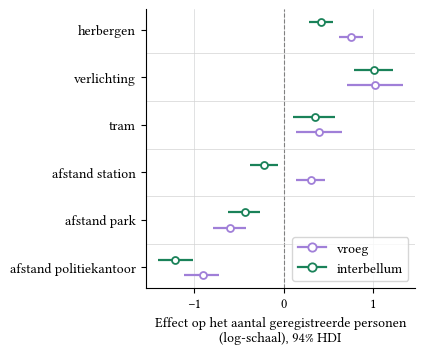

In [24]:
labels = list(VARIABELEN)
OFFSET = {"vroeg": 0.16, "interbellum": -0.16}
KLEUR = {"vroeg": KLEUR_VROEG, "interbellum": KLEUR_LAAT}

fig, ax = plt.subplots(figsize=figsize(1.0, ratio=0.85))

for _, r in effecten.iterrows():
    y = labels.index(r["variabele"]) + OFFSET[r["periode"]]
    ax.plot([r["lo"], r["hi"]], [y, y], color=KLEUR[r["periode"]], lw=1.6, solid_capstyle="butt")
    ax.plot(r["gemiddelde"], y, "o", color=KLEUR[r["periode"]], ms=5,
            markerfacecolor="white", markeredgewidth=1.3)

ax.axvline(0, color="grey", linestyle="--", lw=0.8)
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
ax.invert_yaxis()
ax.set_xlabel("Effect op het aantal geregistreerde personen\n(log-schaal), 94% HDI")

for i in range(1, len(labels)):
    ax.axhline(i - 0.5, color="lightgrey", lw=0.5)

handles = [plt.Line2D([], [], color=KLEUR[p], lw=1.6, marker="o",
                      markerfacecolor="white", markeredgewidth=1.3, label=p)
           for p in ["vroeg", "interbellum"]]
ax.legend(handles=handles, loc="lower right", frameon=True)
ax.grid(axis="x")
ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)

#fig.savefig(OUTPUT / "forestplot_periodes.pdf")
pas_breedte_aan(fig)
fig.savefig(OUTPUT / "6.13_forestplot_periodes.png")
plt.show()

In [25]:
post = results.posterior

VARIABELEN = {
    "herbergen":              "n_herbergen_z",
    "verlichting":            "verlichting_bin",
    "tram":                   "heeft_tram",
    "afstand station":        "afstand_station_z",
    "afstand park":           "afstand_park_z",
    "afstand politiekantoor": "afstand_politie_z",
}

def samples(naam):
    return post[naam].stack(s=("chain", "draw")).values.ravel()

rijen = []
for label, var in VARIABELEN.items():
    nacht = samples(f"{var}:is_nacht")
    lo, hi = az.hdi(nacht, hdi_prob=0.94)
    rijen.append({"variabele": label, "gemiddelde": nacht.mean(), "lo": lo, "hi": hi})

nachteffect = pd.DataFrame(rijen)
print(nachteffect.round(3).to_string(index=False))

             variabele  gemiddelde     lo    hi
             herbergen       0.021 -0.066 0.107
           verlichting      -0.165 -0.351 0.028
                  tram      -0.012 -0.195 0.175
       afstand station       0.022 -0.083 0.132
          afstand park      -0.005 -0.131 0.119
afstand politiekantoor      -0.026 -0.160 0.107


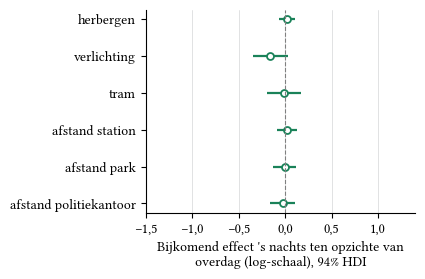

In [26]:
fig, ax = plt.subplots(figsize=figsize(1.0, ratio=0.62))

for i, r in nachteffect.iterrows():
    ax.plot([r["lo"], r["hi"]], [i, i], color=KLEUR_HOOFD, lw=1.6, solid_capstyle="butt")
    ax.plot(r["gemiddelde"], i, "o", color=KLEUR_HOOFD, ms=5,
            markerfacecolor="white", markeredgewidth=1.3)

ax.axvline(0, color="grey", linestyle="--", lw=0.8)
ax.set_xlim(-1.5, 1.4)
ax.set_yticks(range(len(nachteffect)))
ax.set_yticklabels(nachteffect["variabele"])
ax.invert_yaxis()
ax.set_xlabel("Bijkomend effect 's nachts ten opzichte van\noverdag (log-schaal), 94% HDI")
ax.grid(axis="x")
ax.spines[["top", "right"]].set_visible(False)
ax.set_axisbelow(True)

#fig.savefig(OUTPUT / "6.14_nachteffect.pdf")
pas_breedte_aan(fig)
fig.savefig(OUTPUT / "6.14_nachteffect.png")
plt.show()

In [27]:
for kolom in ["n_herbergen", "n_danszalen", "afstand_station", "afstand_park", "afstand_politie"]:
    print(f"{kolom}: sd = {model_data[kolom].std():.1f}, gemiddelde = {model_data[kolom].mean():.1f}")

n_herbergen: sd = 6.5, gemiddelde = 4.2
n_danszalen: sd = 0.2, gemiddelde = 0.0
afstand_station: sd = 394.0, gemiddelde = 644.4
afstand_park: sd = 400.6, gemiddelde = 450.0
afstand_politie: sd = 464.2, gemiddelde = 675.7


In [28]:
print(model_data.groupby("period")["n_danszalen"].describe().round(2))
print("\nSegmenten met minstens één danszaal:")
print(model_data[model_data["n_danszalen"] > 0].groupby("period")["segment_uid"].nunique())

           count  mean   std  min  25%  50%  75%  max
period                                               
interwar  2174.0  0.03  0.22  0.0  0.0  0.0  0.0  4.0
vroeg     2174.0  0.01  0.09  0.0  0.0  0.0  0.0  1.0

Segmenten met minstens één danszaal:
period
interwar    19
vroeg        8
Name: segment_uid, dtype: int64


In [29]:
formula_3w = (
    "n_personen ~ "
    "n_herbergen_z * is_interwar * is_nacht + "
    "n_danszalen_z * is_interwar * is_nacht + "
    "verlichting_bin * is_interwar * is_nacht + "
    "heeft_tram * is_interwar * is_nacht + "
    "afstand_station_z * is_interwar * is_nacht + "
    "afstand_park_z * is_interwar * is_nacht + "
    "afstand_politie_z * is_interwar * is_nacht + "
    "(1 | segment_uid)"
)

model_3w   = bmb.Model(formula_3w, model_data, family="negativebinomial")
results_3w = model_3w.fit(draws=2000, tune=2000, chains=4, target_accept=0.9, cores=1, random_seed=42)

summary_3w = az.summary(results_3w, hdi_prob=0.94)
prob = summary_3w[(summary_3w["r_hat"] > 1.01) | (summary_3w["ess_bulk"] < 400)]
print("Geen convergentieproblemen." if len(prob) == 0 else prob[["mean", "sd", "r_hat", "ess_bulk"]])

Initializing NUTS using jitter+adapt_diag...


Sequential sampling (4 chains in 1 job)


NUTS: [alpha, Intercept, n_herbergen_z, is_interwar, n_herbergen_z:is_interwar, is_nacht, n_herbergen_z:is_nacht, is_interwar:is_nacht, n_herbergen_z:is_interwar:is_nacht, n_danszalen_z, n_danszalen_z:is_interwar, n_danszalen_z:is_nacht, n_danszalen_z:is_interwar:is_nacht, verlichting_bin, verlichting_bin:is_interwar, verlichting_bin:is_nacht, verlichting_bin:is_interwar:is_nacht, heeft_tram, heeft_tram:is_interwar, heeft_tram:is_nacht, heeft_tram:is_interwar:is_nacht, afstand_station_z, afstand_station_z:is_interwar, afstand_station_z:is_nacht, afstand_station_z:is_interwar:is_nacht, afstand_park_z, afstand_park_z:is_interwar, afstand_park_z:is_nacht, afstand_park_z:is_interwar:is_nacht, afstand_politie_z, afstand_politie_z:is_interwar, afstand_politie_z:is_nacht, afstand_politie_z:is_interwar:is_nacht, 1|segment_uid_sigma, 1|segment_uid_offset]


Output()

Output()

In [30]:
post3 = results_3w.posterior

def s3(naam):
    return post3[naam].stack(s=("chain", "draw")).values.ravel()

def hdi_rij(label, periode, dagdeel, waarden):
    lo, hi = az.hdi(waarden, hdi_prob=0.94)
    return {"variabele": label, "periode": periode, "dagdeel": dagdeel,
            "gemiddelde": waarden.mean(), "lo": lo, "hi": hi}

rijen = []
for label, var in VARIABELEN.items():
    hoofd = s3(var)
    inter = s3(f"{var}:is_interwar")
    nacht = s3(f"{var}:is_nacht")
    drie  = s3(f"{var}:is_interwar:is_nacht")
    rijen += [
        hdi_rij(label, "vroeg", "dag", hoofd),
        hdi_rij(label, "vroeg", "nacht", hoofd + nacht),
        hdi_rij(label, "interbellum", "dag", hoofd + inter),
        hdi_rij(label, "interbellum", "nacht", hoofd + inter + nacht + drie),
    ]

effecten3w = pd.DataFrame(rijen)
print(effecten3w.round(2).to_string(index=False))

             variabele     periode dagdeel  gemiddelde    lo    hi
             herbergen       vroeg     dag        0.76  0.62  0.91
             herbergen       vroeg   nacht        0.75  0.59  0.90
             herbergen interbellum     dag        0.41  0.27  0.54
             herbergen interbellum   nacht        0.43  0.29  0.57
           verlichting       vroeg     dag        0.96  0.63  1.31
           verlichting       vroeg   nacht        0.90  0.56  1.27
           verlichting interbellum     dag        0.91  0.68  1.13
           verlichting interbellum   nacht        0.95  0.71  1.18
                  tram       vroeg     dag        0.42  0.15  0.70
                  tram       vroeg   nacht        0.36  0.09  0.64
                  tram interbellum     dag        0.35  0.09  0.60
                  tram interbellum   nacht        0.35  0.09  0.61
       afstand station       vroeg     dag        0.31  0.13  0.48
       afstand station       vroeg   nacht        0.32  0.15  

In [31]:
rijen = []
for label, var in VARIABELEN.items():
    d = s3(f"{var}:is_interwar:is_nacht")
    lo, hi = az.hdi(d, hdi_prob=0.94)
    rijen.append({"variabele": label, "gemiddelde": d.mean(), "lo": lo, "hi": hi,
                  "raakt_nul": lo <= 0 <= hi})

drieweg = pd.DataFrame(rijen)
print(drieweg.round(3).to_string(index=False))

             variabele  gemiddelde     lo    hi  raakt_nul
             herbergen       0.042 -0.142 0.215       True
           verlichting       0.103 -0.382 0.536       True
                  tram       0.054 -0.323 0.434       True
       afstand station       0.003 -0.216 0.222       True
          afstand park      -0.031 -0.287 0.207       True
afstand politiekantoor       0.135 -0.127 0.391       True
